# Predicción multiclase de riesgo cardiovascular

**Práctica 1 · Machine Learning · Máster en Inteligencia Artificial (UMU) · Curso 2026/2027**

**Objetivo:** clasificar a los pacientes en tres niveles de riesgo cardiovascular a partir de 27 variables sociodemográficas, clínicas, analíticas y de estilo de vida.

| Clase | Significado |
|---|---|
| 0 | Bajo riesgo |
| 1 | Riesgo moderado |
| 2 | Alto riesgo |

**Dataset:** `data/enfermedad_cardiovascular.csv` (2.254 pacientes, 27 variables de entrada + 1 objetivo).

## 1. Análisis exploratorio de datos (EDA)

Objetivo de esta fase: auditar la calidad del dataset e identificar todas las problemáticas presentes en las variables (apartado 3.1 del enunciado).

### 1.1. Librerías y semilla

Importar las librerías necesarias y fijar la semilla para garantizar la reproducibilidad.



In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt

%matplotlib inline

semilla=42
np.random.seed(semilla)


### 1.2. Carga de datos

Cargar el CSV en un DataFrame.

In [11]:
url = ( '../data/enfermedad_cardiovascular.csv')
datos = pd.read_csv(url, sep=',')
datos.head(3)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2


### 1.3. Descripción del dataset

Ver las dimensiones, tipos de datos, valores estadísticos y valores duplicados.



In [12]:
datos.info()
display(datos.describe(include='all').T)
display(datos.shape)
datos.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  proteina_c_rea

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,2254.0,NaN,NaN,NaN,56.688287,14.448018,9.8,47.2,56.9,66.475,103.5
presion_sistolica,2254.0,NaN,NaN,NaN,132.315186,26.931005,52.2,115.3,129.65,143.9,231.36
presion_diastolica,2254.0,NaN,NaN,NaN,82.167524,13.084058,30.8,73.6,82.1,91.1,122.5
colesterol_total,2254.0,NaN,NaN,NaN,228.133829,62.725948,61.1,188.2,221.2,252.5,448.59
colesterol_hdl,2254.0,NaN,NaN,NaN,47.2252,15.991614,-8.8,36.7,47.3,58.2,106.3
colesterol_ldl,2119.0,NaN,NaN,NaN,135.638603,36.732756,6.1,111.4,135.5,161.4,266.7
trigliceridos,2254.0,NaN,NaN,NaN,176.657391,72.735893,-35.7,133.05,170.0,208.1,452.7
glucosa_ayunas,2142.0,NaN,NaN,NaN,104.10733,24.939696,32.0,86.3,103.75,120.475,194.0
indice_masa_corporal,2254.0,NaN,NaN,NaN,28.09339,6.470585,3.6,23.8,28.0,32.5,50.6
frecuencia_cardiaca_reposo,2254.0,NaN,NaN,NaN,73.66819,12.762546,25.8,65.0,73.1,82.3,112.7


(2254, 28)

np.int64(0)

El dataset tiene 2254 filas y 28 columnas, no contiene duplicados y hay valores nulos en las columnas `colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`.

En las columnas `min` y `max` de `describe()` aparecen valores anómalos:

- **Mínimos:** valores negativos en `colesterol_hdl`, `trigliceridos` y `consumo_alcohol_semanal`, un IMC de 3.6 y pacientes menores de edad.
- **Máximos:** `frecuencia_ejercicio_semanal` con valores mayores a 7 días, y máximos poco comunes en `presion_sistolica` (231.36), `colesterol_total` (448.59), `trigliceridos` (452.7) y `acido_urico` (12.29).




### 1.4. Distribución de clases

Ver cuántos pacientes hay en cada clase de riesgo y en qué porcentaje, para comprobar si el dataset está desbalanceado.

riesgo_cardiovascular
0    1127
1     676
2     451
Name: count, dtype: int64

riesgo_cardiovascular
0    0.500000
1    0.299911
2    0.200089
Name: proportion, dtype: float64

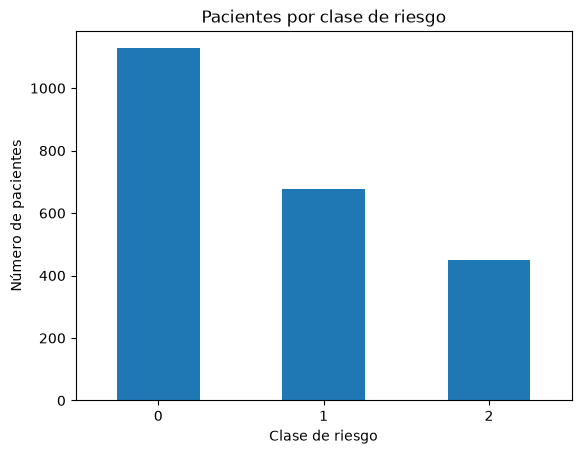

In [13]:
count_classes = datos['riesgo_cardiovascular'].value_counts(sort=True)
display(count_classes)
count_classes.plot(kind = 'bar', rot=0)

display(datos['riesgo_cardiovascular'].value_counts(normalize=True))


plt.title("Pacientes por clase de riesgo")
plt.xlabel("Clase de riesgo")
plt.ylabel("Número de pacientes");

El dataset está desbalanceado: la clase 0 (bajo riesgo) tiene 1127 pacientes (50 %), la clase 1 (riesgo moderado) 676 (30 %) y la clase 2 (alto riesgo) 451 (20 %), siendo el alto riesgo la clase minoritaria.

